# UCLASS Preprocessing (cross-corpus test set)

Gets the UCLASS corpus ready to test the models trained on SEP-28k-Extended. The clips have already
been cut into 3-second SEP-28k-style WAV files, so this is simpler than the SEP-28k pipeline: there
are no episodes to slice, no annotator votes and no quality flags.

Uses the same 6 classes, class order and MFCC settings as the model notebooks (`common.ipynb`).

Saves to `feature_cache/`:
- `X_uclass_v1.npy`, `y_uclass_v1.npy`: mean MFCC features and labels (used by Model 3)
- `meta_uclass_v1.csv`: one row per clip with speaker, age and age group, in the same order as
  `X`/`y`. Models 1 and 2 build their own features from this list.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%run common.ipynb  # shared settings and helper functions

## 1. Labels, speaker and age

The filename holds the speaker id and age, e.g. `M_0030_16y4m_1_dysfluent_000.wav` is speaker
`M_0030`, aged 16 years 4 months.

In [2]:
labels = pd.read_csv(UCLASS_ROOT / "clips" / "labels.csv")

parts = labels["filepath"].str.extract(r"(M_\d+)_(\d+)y(\d+)m")
labels["speaker_id"] = parts[0]
labels["age_years"] = parts[1].astype(float) + parts[2].astype(float) / 12
labels["age_group"] = np.where(labels["age_years"] < 18, "Child (<18)", "Adult (18+)")

print(f"Total clips: {len(labels)}")
print(f"Filenames without speaker/age: {labels['speaker_id'].isna().sum()}")
print(f"Unique speakers: {labels['speaker_id'].nunique()}")
labels[["filepath", "speaker_id", "age_years", "age_group"]].head()

Total clips: 4712
Filenames without speaker/age: 0
Unique speakers: 16


,filepath,speaker_id,age_years,age_group
0,clips/clips/M_0030_16y4m_1_dysfluent_000.wav,M_0030,16.333333,Child (<18)
1,clips/clips/M_0030_16y4m_1_dysfluent_001.wav,M_0030,16.333333,Child (<18)
2,clips/clips/M_0030_16y4m_1_dysfluent_002.wav,M_0030,16.333333,Child (<18)
3,clips/clips/M_0030_16y4m_1_dysfluent_003.wav,M_0030,16.333333,Child (<18)
4,clips/clips/M_0030_16y4m_1_dysfluent_004.wav,M_0030,16.333333,Child (<18)


## 2. One label per clip

UCLASS has one annotator, so each class is just 0 or 1, but a clip can have more than one class set
(e.g. Block and SoundRep together). To match the SEP-28k labels, `argmax` is taken over the same
class order, so the earlier class in `CLASS_NAMES` wins. This means a few clips lose one of their
labels, which is a limitation worth mentioning.

In [3]:
n_positive = (labels[CLASS_NAMES] > 0).sum(axis=1)
print("Clips by number of positive labels:")
print(n_positive.value_counts().sort_index())

labels = labels[n_positive > 0].copy()
labels["label"] = np.argmax(labels[CLASS_NAMES].values, axis=1)
print_class_counts(labels["label"], "\nClass distribution:")

Clips by number of positive labels:
1    3081
2    1065
3     483
4      75
5       8
Name: count, dtype: int64

Class distribution:
  0 Prolongation: 443
  1 Block: 1132
  2 SoundRep: 720
  3 WordRep: 54
  4 Interjection: 141
  5 NoStutteredWords: 2222


## 3. Check the audio files exist

`filepath` is relative to the UCLASS version folder (`versions/3/`).

In [4]:
labels["wav_path"] = labels["filepath"].map(lambda p: UCLASS_ROOT / p)

missing = ~labels["wav_path"].map(lambda p: p.exists())
print(f"Missing WAV files: {missing.sum()} / {len(labels)}")
labels = labels[~missing].reset_index(drop=True)
print(f"Usable clips: {len(labels)}")

Missing WAV files: 0 / 4712
Usable clips: 4712


## 4. Speaker ages and fluent/dysfluent balance

Same plots as Figures 7-9 in the methodology.

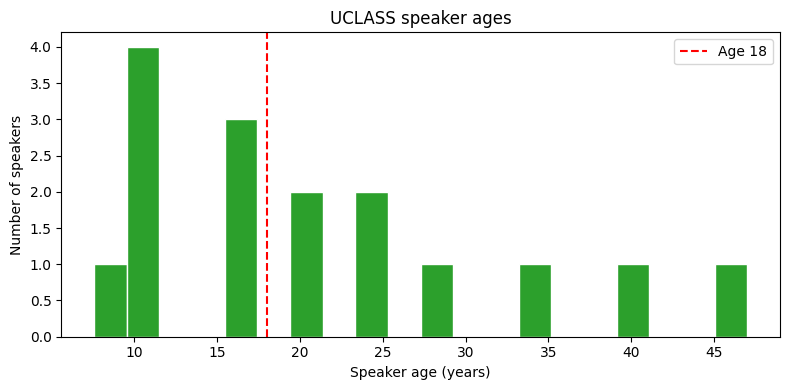

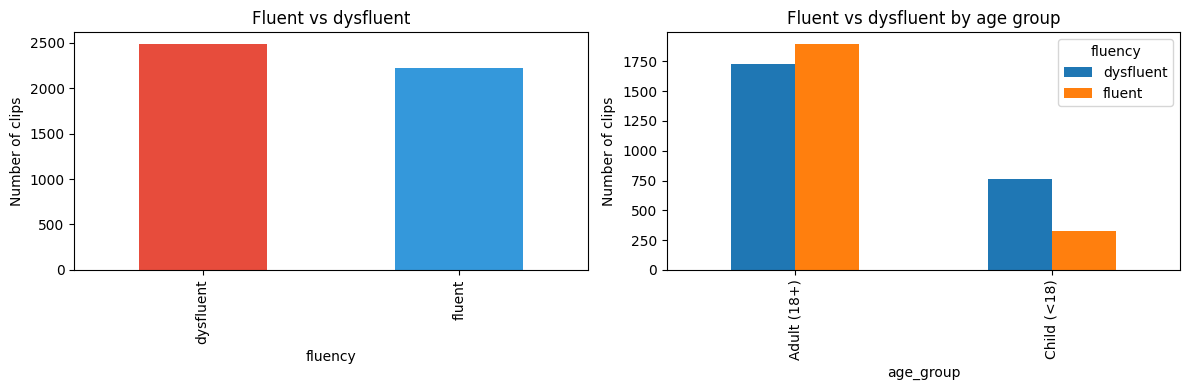

fluency      dysfluent  fluent
age_group                     
Adult (18+)       1726    1899
Child (<18)        764     323


In [5]:
speaker_ages = labels.drop_duplicates("speaker_id")["age_years"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(speaker_ages, bins=20, color="#2ca02c", edgecolor="white")
ax.axvline(18, color="red", linestyle="--", label="Age 18")
ax.set_xlabel("Speaker age (years)")
ax.set_ylabel("Number of speakers")
ax.set_title("UCLASS speaker ages")
ax.legend()
plt.tight_layout()
plt.show()

labels["fluency"] = np.where(labels["label"] == FLUENT, "fluent", "dysfluent")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels["fluency"].value_counts().plot.bar(ax=axes[0], color=["#e74c3c", "#3498db"])
axes[0].set_title("Fluent vs dysfluent")
axes[0].set_ylabel("Number of clips")

pd.crosstab(labels["age_group"], labels["fluency"]).plot.bar(ax=axes[1])
axes[1].set_title("Fluent vs dysfluent by age group")
axes[1].set_ylabel("Number of clips")
plt.tight_layout()
plt.show()

print(pd.crosstab(labels["age_group"], labels["fluency"]))

## 5. MFCC features

Same as Model 3: 40 MFCCs averaged over time. The clips should already be exactly 3 seconds, but
they are padded/cut anyway to be safe.

In [6]:
def build():
    X = np.array([mfcc(clip).mean(axis=1) for clip in uclass_clips(labels)])
    labels.to_csv(CACHE_DIR / "meta_uclass_v1.csv", index=False)  # same row order as X and y
    return X, labels["label"].to_numpy()


X_uclass, y_uclass = cached("X_uclass_v1", "y_uclass_v1", build)
print(f"X_uclass: {X_uclass.shape}, y_uclass: {y_uclass.shape}")

X_uclass_v1: loaded from cache
X_uclass: (4712, 40), y_uclass: (4712,)


In [7]:
meta = pd.read_csv(CACHE_DIR / "meta_uclass_v1.csv")
print(f"Saved metadata rows: {len(meta)}")
print(f"Child clips: {(meta['age_group'] == 'Child (<18)').sum()}")
print(f"Adult clips: {(meta['age_group'] == 'Adult (18+)').sum()}")
meta.head()

Saved metadata rows: 4712
Child clips: 1087
Adult clips: 3625


,filepath,Block,Prolongation,SoundRep,WordRep,Interjection,NoStutteredWords,speaker_id,age_years,age_group,label,wav_path,fluency
0,clips/clips/M_0030_16y4m_1_dysfluent_000.wav,1,0,1,0,0,0,M_0030,16.333333,Child (<18),1,uclass-stuttered-speech-clips-sep-28k-format\v...,dysfluent
1,clips/clips/M_0030_16y4m_1_dysfluent_001.wav,1,0,1,0,0,0,M_0030,16.333333,Child (<18),1,uclass-stuttered-speech-clips-sep-28k-format\v...,dysfluent
2,clips/clips/M_0030_16y4m_1_dysfluent_002.wav,1,0,1,0,0,0,M_0030,16.333333,Child (<18),1,uclass-stuttered-speech-clips-sep-28k-format\v...,dysfluent
3,clips/clips/M_0030_16y4m_1_dysfluent_003.wav,1,0,1,0,0,0,M_0030,16.333333,Child (<18),1,uclass-stuttered-speech-clips-sep-28k-format\v...,dysfluent
4,clips/clips/M_0030_16y4m_1_dysfluent_004.wav,0,1,0,0,1,0,M_0030,16.333333,Child (<18),0,uclass-stuttered-speech-clips-sep-28k-format\v...,dysfluent
